In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

In [3]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

Regression: Homo_link

######Askscience

In [ ]:

science_df = pd.read_csv('./result/weekly/all features/fill_nan/version2/askscience1.csv', parse_dates=["week"], index_col="week")

df = science_df.sort_index()


train_size = int(len(df) * 0.8)


train = df.iloc[:train_size]
#test = df.iloc[train_size-4:]

test  = df.iloc[train_size:]




print(df.head())

            Home_dist_filled  Home_link_filled  Polar_filled  \
week                                                           
2010-04-05          0.281593          0.391667      0.057601   
2010-04-12          0.333333          0.666667      0.000000   
2010-04-19          0.307463          0.529167      0.028800   
2010-04-26         -0.013889          0.611111      0.006944   
2010-05-03         -1.000000          0.000000      0.000000   

            entropy_x_filled  Gini_filled  taaco_filled  entropy_y_filled  \
week                                                                        
2010-04-05          6.555776     0.731673      0.402828          2.004886   
2010-04-12          6.214003     0.738410      0.424197          1.435371   
2010-04-19          6.384890     0.735042      0.413512          1.720129   
2010-04-26          6.554289     0.669314      0.357411          2.401058   
2010-05-03          6.446841     0.819858      0.425317          0.000000   

           

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

def stationarity_test(series, name="", alpha=0.05):
    print(f"\n====== 平稳性检验：{name} ======")

    # Drop NA
    series = series.dropna()

    # ---- ADF ----
    adf_result = adfuller(series, autolag='AIC')
    adf_stat, adf_p = adf_result[0], adf_result[1]
    print(f"ADF: statistic={adf_stat:.4f}, p={adf_p:.4f}")
    if adf_p < alpha:
        print(" → ADF 结论：拒绝单位根假设 → 序列平稳")
        adf_flag = True
    else:
        print(" → ADF 结论：无法拒绝单位根假设 → 序列非平稳")
        adf_flag = False

    # ---- KPSS ----
    try:
        kpss_result = kpss(series, regression='ct')
        kpss_stat, kpss_p = kpss_result[0], kpss_result[1]
        print(f"KPSS: statistic={kpss_stat:.4f}, p={kpss_p:.4f}")
        if kpss_p < alpha:
            print(" → KPSS 结论：拒绝平稳假设 → 序列非平稳")
            kpss_flag = False
        else:
            print(" → KPSS 结论：无法拒绝平稳假设 → 序列平稳")
            kpss_flag = True
    except:
        print("KPSS 无法运行（序列过短或常数列）")
        kpss_flag = False

    
    print("\n📌 综合判断：", end="")
    if adf_flag and kpss_flag:
        print("序列显著平稳 ✔")
    elif (not adf_flag) and (not kpss_flag):
        print("序列显著非平稳，需要差分")
    else:
        print("结果不一致：可能为趋势平稳 → 建议差分或加入趋势项")

    print("=====================================\n")


# -------------------------

# -------------------------


cols_to_test = ["Polar_filled","Home_dist_filled","Home_link_filled"]  


for col in cols_to_test:
    stationarity_test(df[col], name=col)


====== 平稳性检验：Polar_filled ======
ADF: statistic=-12.2748, p=0.0000
 → ADF 结论：拒绝单位根假设 → 序列平稳
KPSS: statistic=0.0713, p=0.1000
 → KPSS 结论：无法拒绝平稳假设 → 序列平稳

📌 综合判断：序列显著平稳 ✔


====== 平稳性检验：Home_dist_filled ======
ADF: statistic=-4.8205, p=0.0000
 → ADF 结论：拒绝单位根假设 → 序列平稳
KPSS: statistic=0.0897, p=0.1000
 → KPSS 结论：无法拒绝平稳假设 → 序列平稳

📌 综合判断：序列显著平稳 ✔


====== 平稳性检验：Home_link_filled ======
ADF: statistic=-2.5954, p=0.0939
 → ADF 结论：无法拒绝单位根假设 → 序列非平稳
KPSS: statistic=0.7054, p=0.0100
 → KPSS 结论：拒绝平稳假设 → 序列非平稳

📌 综合判断：序列显著非平稳，需要差分



C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(series, regression='ct')
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(series, regression='ct')
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, regression='ct')


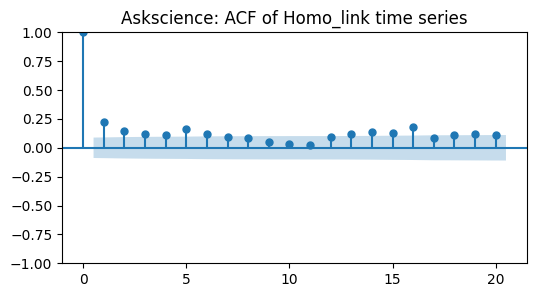

In [ ]:

fig, ax = plt.subplots(figsize=(6, 3))  
plot_acf(train["Home_link_filled"], lags=20, ax=ax)  
plt.title("Askscience: ACF of Homo_link time series")
plt.show()

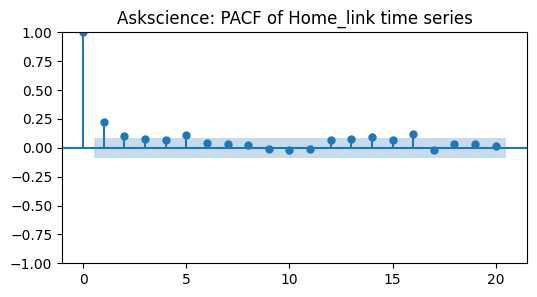

In [ ]:


from statsmodels.graphics.tsaplots import plot_pacf


fig, ax = plt.subplots(figsize=(6, 3))  
plot_pacf(train["Home_link_filled"], lags=20,ax=ax)  
plt.title("Askscience: PACF of Home_link time series")
plt.show()

In [ ]:


from statsmodels.stats.stattools import durbin_watson

dw_stat = durbin_watson(train["Home_link_filled"])
print(f"Durbin-Watson 统计量: {dw_stat}")


Durbin-Watson 统计量: 0.29264130065172556


In [ ]:


from statsmodels.stats.diagnostic import acorr_ljungbox

lb_test = acorr_ljungbox(train["Home_link_filled"], lags=[1,2,3,4,5,6,7,8,9, 10,11,12,13,14, 15], return_df=True)
print(lb_test)

       lb_stat     lb_pvalue
1    23.813745  1.061220e-06
2    34.620647  3.035443e-08
3    42.130717  3.763869e-09
4    48.471678  7.525347e-10
5    60.959390  7.698548e-12
6    67.677568  1.223085e-12
7    72.249188  5.181575e-13
8    75.847379  3.336687e-13
9    76.995307  6.372124e-13
10   77.511127  1.540832e-12
11   77.914383  3.729553e-12
12   82.290699  1.506359e-12
13   89.338141  1.870165e-13
14   99.407905  6.157924e-15
15  108.074865  3.773037e-16


In [ ]:

from pmdarima import auto_arima

best_model = auto_arima(train["Home_link_filled"], seasonal=False, trace=True, stepwise=True)
print(best_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-610.120, Time=0.24 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-354.703, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-468.098, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-609.712, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-356.703, Time=0.04 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-608.537, Time=0.14 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-612.596, Time=0.19 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-614.106, Time=0.16 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-613.650, Time=0.17 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-511.968, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-615.712, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=-611.511, Time=0.04 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=-470.098, Time=0.02 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=-614.144, Time=0.09 sec
 ARIMA(1,1,2)(0,0,0)[0]          

                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  491
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 310.856
Date:                Tue, 22 Sep 2026   AIC                           -615.712
Time:                        02:28:47   BIC                           -603.129
Sample:                    04-05-2010   HQIC                          -610.770
                         - 08-26-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1184      0.042      2.787      0.005       0.035       0.202
ma.L1         -0.9605      0.018    -54.164      0.000      -0.995      -0.926
sigma2         0.0164      0.001     19.262      0.0

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\4137581079.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-

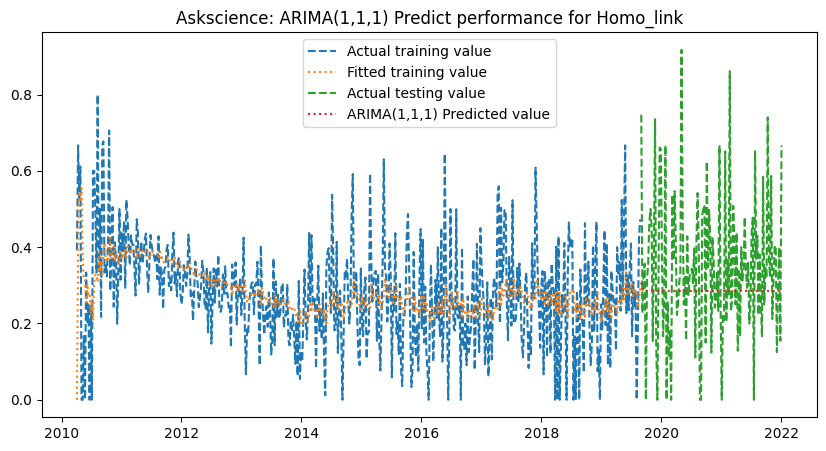

In [ ]:


from statsmodels.tsa.arima.model import ARIMA




model = ARIMA(train["Home_link_filled"], order=(1, 1, 1))  
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues


forecast_steps = len(test)
predictions = result.forecast(steps=forecast_steps)

predictions = pd.Series(predictions, index=test.index)


plt.figure(figsize=(10, 5))
plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")
plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")


plt.plot(predictions.index, predictions, label="ARIMA(1,1,1) Predicted value", linestyle="dotted")

plt.title("Askscience: ARIMA(1,1,1) Predict performance for Homo_link")
plt.legend()
plt.show()


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  491
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 310.856
Date:                Tue, 22 Sep 2026   AIC                           -615.712
Time:                        02:29:07   BIC                           -603.129
Sample:                    04-05-2010   HQIC                          -610.770
                         - 08-26-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1184      0.042      2.787      0.005       0.035       0.202
ma.L1         -0.9605      0.018    -54.164      0.000      -0.995      -0.926
sigma2         0.0164      0.001     19.262      0.0

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\1253697400.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-d

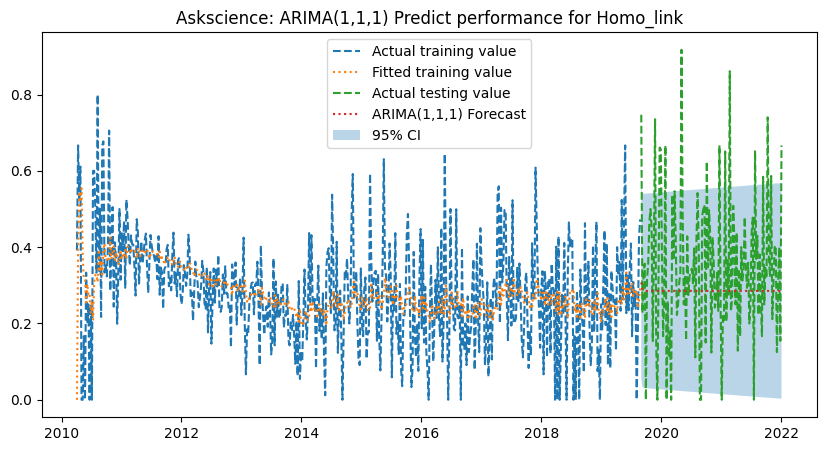

In [ ]:

model = ARIMA(train["Home_link_filled"], order=(1, 1, 1))  
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues




forecast_steps = len(test)
#predictions = result.forecast(steps=forecast_steps)
forecast_res = result.get_forecast(steps=forecast_steps)

pred_mean = forecast_res.predicted_mean
pred_ci = forecast_res.conf_int(alpha=0.05)  # 95% CI

#predictions = pd.Series(predictions, index=test.index)
pred_mean = pd.Series(pred_mean, index=test.index)
pred_ci.index = test.index


plt.figure(figsize=(10, 5))

plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")

plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")
plt.plot(pred_mean.index, pred_mean, label="ARIMA(1,1,1) Forecast", linestyle="dotted")

plt.fill_between(
    test.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.3,
    label="95% CI"
)

plt.title("Askscience: ARIMA(1,1,1) Predict performance for Homo_link")
plt.legend()
plt.show()


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro

residuals = result.resid

ljung_box_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].values[0]


dw_stat = durbin_watson(residuals)


shapiro_p = shapiro(residuals)[1]

print(f"Ljung-Box p-value: {ljung_box_p}")
print(f"Durbin-Watson stat: {dw_stat}")
print(f"Shapiro-Wilk p-value: {shapiro_p}")

Ljung-Box p-value: 0.7786847214354644
Durbin-Watson stat: 1.9502051361928314
Shapiro-Wilk p-value: 1.2267257716302993e-06


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
'''

mae = mean_absolute_error(test_filtered["Polar_filled"], predictions)
rmse = np.sqrt(mean_squared_error(test_filtered["Polar_filled"], predictions))


print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
'''


eval_df = pd.concat(
    [test["Home_link_filled"], predictions],
    axis=1
)
eval_df.columns = ["y_true", "y_pred"]


eval_df = eval_df.dropna()


mae = mean_absolute_error(eval_df["y_true"], eval_df["y_pred"])
rmse = np.sqrt(mean_squared_error(eval_df["y_true"], eval_df["y_pred"]))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.1479
RMSE: 0.1941


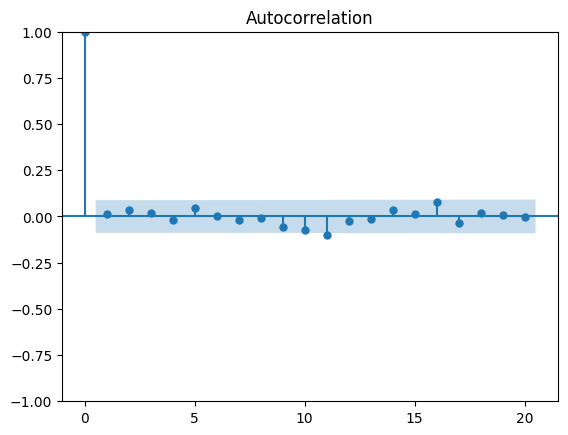

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


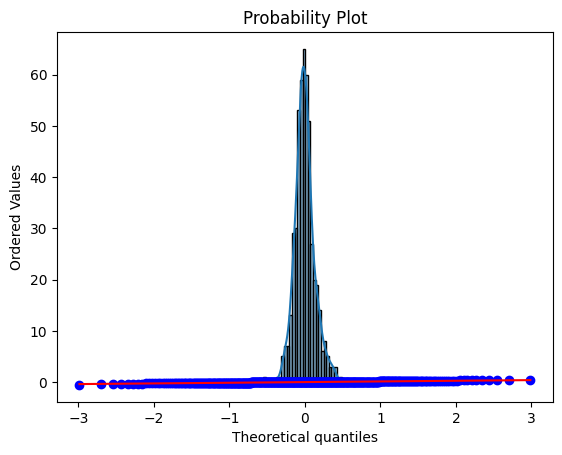

In [ ]:


import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

residuals = result.resid


plot_acf(residuals, lags=20)
plt.show()


sns.histplot(residuals, kde=True)
stats.probplot(residuals, dist="norm", plot=plt)
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro

residuals = result.resid

ljung_box_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].values[0]


dw_stat = durbin_watson(residuals)


shapiro_p = shapiro(residuals)[1]

print(f"Ljung-Box p-value: {ljung_box_p}")
print(f"Durbin-Watson stat: {dw_stat}")
print(f"Shapiro-Wilk p-value: {shapiro_p}")

Ljung-Box p-value: 0.7786847214354644
Durbin-Watson stat: 1.9502051361928314
Shapiro-Wilk p-value: 1.2267257716302993e-06


In [ ]:



X = df[["entropy_x_filled","Gini_filled","taaco_filled","density_filled",
                "in-group identity_filled","out-group identity_filled","gender identity_filled","queer identity_filled","disability identity_filled","body size and physical identity_filled","relational identity_filled",
                "professional identity_filled","partisan identity_filled",
                "generational identity_filled","ideological identity_filled","racial identity_filled","class identity_filled","religious identity_filled","national identity_filled",
                "anger_filled","anticipation_filled","disgust_filled","fear_filled","joy_filled","sadness_filled","surprise_filled","trust_filled"]]  
X = sm.add_constant(X)  
y = df["Home_link_filled"]


model = sm.OLS(y, X).fit()
print(model.summary())  

                            OLS Regression Results                            
Dep. Variable:       Home_link_filled   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     4.560
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.12e-12
Time:                        02:30:24   Log-Likelihood:                 358.99
No. Observations:                 614   AIC:                            -662.0
Df Residuals:                     586   BIC:                            -538.2
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [ ]:
exog_train = train[["entropy_x_filled","taaco_filled","disability identity_filled","racial identity_filled"
    ]]  

best_model = auto_arima(train["Home_link_filled"],exogenous=exog_train, seasonal=False, trace=True, stepwise=True)
print(best_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-610.120, Time=0.25 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-354.703, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-468.098, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-609.712, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-356.703, Time=0.04 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-608.537, Time=0.14 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-612.596, Time=0.19 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-614.106, Time=0.16 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-613.650, Time=0.16 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-511.968, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-615.712, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=-611.511, Time=0.04 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=-470.098, Time=0.02 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=-614.144, Time=0.09 sec
 ARIMA(1,1,2)(0,0,0)[0]          

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  491
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 325.467
Date:                Tue, 22 Sep 2026   AIC                           -636.933
Time:                        02:32:50   BIC                           -607.572
Sample:                    04-05-2010   HQIC                          -625.402
                         - 08-26-2019                                         
Covariance Type:                  opg                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
entropy_x_filled               0.1214      0.027      4.458      0.000       0.068       0.175
taaco_filled                  -0.8347      0.232     -3.602      0.000      -1.289 

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\2485263867.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


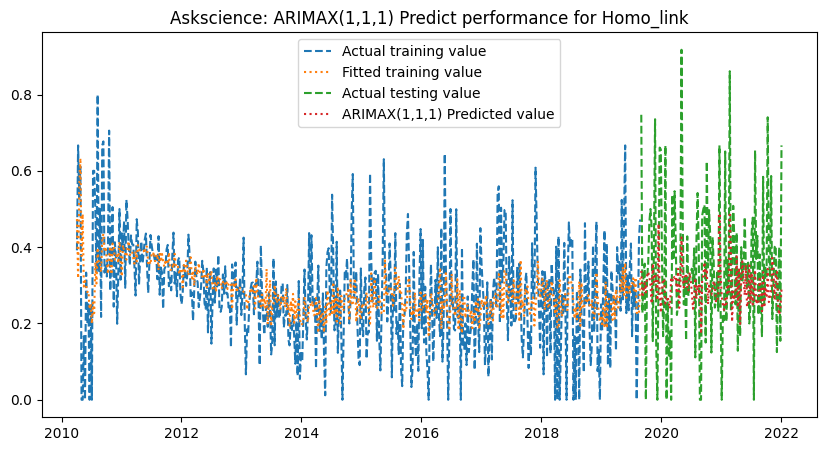

In [ ]:
from statsmodels.tsa.arima.model import ARIMA


exog_train = train[["entropy_x_filled","taaco_filled","disability identity_filled","racial identity_filled"]]  
exog_test = test[["entropy_x_filled","taaco_filled","disability identity_filled","racial identity_filled"]]


model = ARIMA(train["Home_link_filled"], order=(1,1,1), exog=exog_train)
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues

assert exog_test.shape[0] == len(test)
assert all(exog_test.index == test.index)

forecast_steps = len(test)

predictions = result.forecast(
    steps=forecast_steps,
    exog=exog_test
)

predictions = pd.Series(predictions, index=test.index)


import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")
plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")


plt.plot(predictions.index, predictions,
        label="ARIMAX(1,1,1) Predicted value", linestyle="dotted")


plt.legend()
plt.title("Askscience: ARIMAX(1,1,1) Predict performance for Homo_link")
plt.show()



c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  491
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 325.467
Date:                Tue, 22 Sep 2026   AIC                           -636.933
Time:                        02:39:42   BIC                           -607.572
Sample:                    04-05-2010   HQIC                          -625.402
                         - 08-26-2019                                         
Covariance Type:                  opg                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
entropy_x_filled               0.1214      0.027      4.458      0.000       0.068       0.175
taaco_filled                  -0.8347      0.232     -3.602      0.000      -1.289 

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\2483441050.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


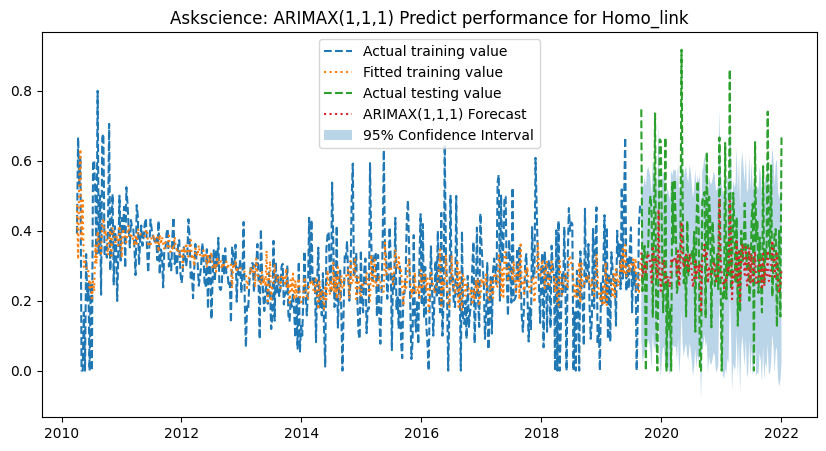

In [ ]:
from statsmodels.tsa.arima.model import ARIMA


exog_train = train[["entropy_x_filled","taaco_filled","disability identity_filled","racial identity_filled"]]  
exog_test = test[["entropy_x_filled","taaco_filled","disability identity_filled","racial identity_filled"]]


model = ARIMA(train["Home_link_filled"], order=(1,1,1), exog=exog_train)
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues

assert exog_test.shape[0] == len(test)
assert all(exog_test.index == test.index)

# =========================

# =========================
forecast_steps = len(test)

forecast_res = result.get_forecast(
    steps=forecast_steps,
    exog=exog_test
)

pred_mean = forecast_res.predicted_mean
pred_ci = forecast_res.conf_int(alpha=0.05)  # 95% CI


pred_mean = pd.Series(pred_mean, index=test.index)
pred_ci.index = test.index

# =========================

# =========================
plt.figure(figsize=(10, 5))

plt.plot(
    train.index,
    train["Home_link_filled"],
    label="Actual training value",
    linestyle="--"
)

plt.plot(
    train.index,
    train["Home_link_predicted"],
    label="Fitted training value",
    linestyle="dotted"
)

plt.plot(
    test.index,
    test["Home_link_filled"],
    label="Actual testing value",
    linestyle="--"
)

plt.plot(
    pred_mean.index,
    pred_mean,
    label="ARIMAX(1,1,1) Forecast",
    linestyle="dotted"
)

plt.fill_between(
    test.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.3,
    label="95% Confidence Interval"
)




plt.legend()
plt.title("Askscience: ARIMAX(1,1,1) Predict performance for Homo_link")
plt.show()



In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro

residuals = result.resid

ljung_box_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].values[0]


dw_stat = durbin_watson(residuals)


shapiro_p = shapiro(residuals)[1]

print(f"Ljung-Box p-value: {ljung_box_p}")
print(f"Durbin-Watson stat: {dw_stat}")
print(f"Shapiro-Wilk p-value: {shapiro_p}")

Ljung-Box p-value: 0.3977330239876753
Durbin-Watson stat: 1.9973880671605515
Shapiro-Wilk p-value: 4.49997315854489e-07


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


eval_df = pd.concat(
    [test["Home_link_filled"], predictions],
    axis=1
)
eval_df.columns = ["y_true", "y_pred"]


eval_df = eval_df.dropna()


mae = mean_absolute_error(eval_df["y_true"], eval_df["y_pred"])
rmse = np.sqrt(mean_squared_error(eval_df["y_true"], eval_df["y_pred"]))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.1396
RMSE: 0.1802


Conspiracy

In [ ]:

conspiracy_df = pd.read_csv('./result/weekly/all features/fill_nan/version2/conspiracy1.csv', parse_dates=["week"], index_col="week")

df = conspiracy_df.sort_index()


train_size = int(len(df) * 0.8)


train = df.iloc[:train_size]


test = df.iloc[train_size:]




print(df.head())

            Home_dist_filled  Home_link_filled  Polar_filled  \
week                                                           
2009-06-15         -0.428571               1.0     -0.428571   
2009-06-22         -0.428571               1.0     -0.428571   
2009-06-29         -0.428571               1.0     -0.428571   
2009-07-06         -0.428571               1.0     -0.428571   
2009-07-13         -0.428571               1.0     -0.428571   

            entropy_x_filled  Gini_filled  taaco_filled  entropy_y_filled  \
week                                                                        
2009-06-15           5.77524     0.666168      0.328952               0.0   
2009-06-22           5.77524     0.666168      0.328952               0.0   
2009-06-29           5.77524     0.666168      0.328952               0.0   
2009-07-06           5.77524     0.666168      0.328952               0.0   
2009-07-13           5.77524     0.666168      0.328952               0.0   

           

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

def stationarity_test(series, name="", alpha=0.05):
    print(f"\n====== 平稳性检验：{name} ======")

    # Drop NA
    series = series.dropna()

    # ---- ADF ----
    adf_result = adfuller(series, autolag='AIC')
    adf_stat, adf_p = adf_result[0], adf_result[1]
    print(f"ADF: statistic={adf_stat:.4f}, p={adf_p:.4f}")
    if adf_p < alpha:
        print(" → ADF 结论：拒绝单位根假设 → 序列平稳")
        adf_flag = True
    else:
        print(" → ADF 结论：无法拒绝单位根假设 → 序列非平稳")
        adf_flag = False

    # ---- KPSS ----
    try:
        kpss_result = kpss(series, regression='ct')
        kpss_stat, kpss_p = kpss_result[0], kpss_result[1]
        print(f"KPSS: statistic={kpss_stat:.4f}, p={kpss_p:.4f}")
        if kpss_p < alpha:
            print(" → KPSS 结论：拒绝平稳假设 → 序列非平稳")
            kpss_flag = False
        else:
            print(" → KPSS 结论：无法拒绝平稳假设 → 序列平稳")
            kpss_flag = True
    except:
        print("KPSS 无法运行（序列过短或常数列）")
        kpss_flag = False

    
    print("\n📌 综合判断：", end="")
    if adf_flag and kpss_flag:
        print("序列显著平稳 ✔")
    elif (not adf_flag) and (not kpss_flag):
        print("序列显著非平稳，需要差分")
    else:
        print("结果不一致：可能为趋势平稳 → 建议差分或加入趋势项")

    print("=====================================\n")


# -------------------------

# -------------------------


cols_to_test = ["Polar_filled","Home_dist_filled","Home_link_filled"]  


for col in cols_to_test:
    stationarity_test(df[col], name=col)


====== 平稳性检验：Polar_filled ======
ADF: statistic=-6.6044, p=0.0000
 → ADF 结论：拒绝单位根假设 → 序列平稳
KPSS: statistic=0.0406, p=0.1000
 → KPSS 结论：无法拒绝平稳假设 → 序列平稳

📌 综合判断：序列显著平稳 ✔


====== 平稳性检验：Home_dist_filled ======
ADF: statistic=-6.2444, p=0.0000
 → ADF 结论：拒绝单位根假设 → 序列平稳
KPSS: statistic=0.0440, p=0.1000
 → KPSS 结论：无法拒绝平稳假设 → 序列平稳

📌 综合判断：序列显著平稳 ✔


====== 平稳性检验：Home_link_filled ======
ADF: statistic=-4.9094, p=0.0000
 → ADF 结论：拒绝单位根假设 → 序列平稳
KPSS: statistic=0.3899, p=0.0100
 → KPSS 结论：拒绝平稳假设 → 序列非平稳

📌 综合判断：结果不一致：可能为趋势平稳 → 建议差分或加入趋势项



C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(series, regression='ct')
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(series, regression='ct')
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3463837345.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, regression='ct')


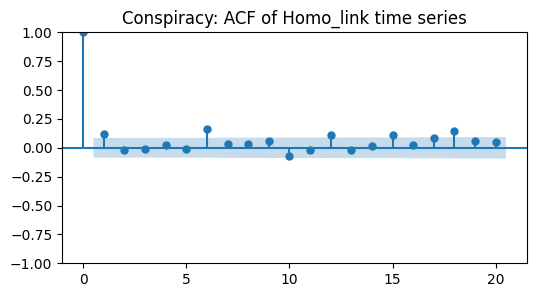

In [ ]:

fig, ax = plt.subplots(figsize=(6, 3)) 
plot_acf(train["Home_link_filled"], lags=20,ax=ax)  
plt.title("Conspiracy: ACF of Homo_link time series")
plt.show()

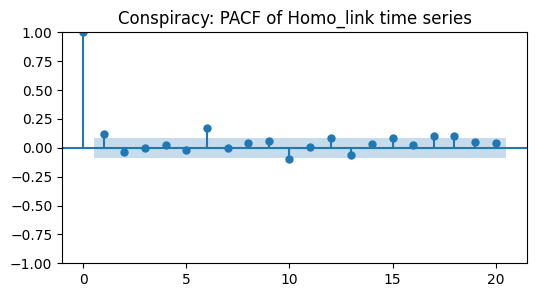

In [ ]:


from statsmodels.graphics.tsaplots import plot_pacf


fig, ax = plt.subplots(figsize=(6, 3)) 
plot_pacf(train["Home_link_filled"], lags=20,ax=ax)  
plt.title("Conspiracy: PACF of Homo_link time series")
plt.show()

In [ ]:


from statsmodels.stats.stattools import durbin_watson

dw_stat = durbin_watson(train["Home_link_filled"])
print(f"Durbin-Watson 统计量: {dw_stat}")


Durbin-Watson 统计量: 0.05310517047892758


In [ ]:


from statsmodels.stats.diagnostic import acorr_ljungbox

lb_test = acorr_ljungbox(train["Home_link_filled"], lags=[1,2,3,4,5,6,7,8,9, 10,11,12,13,14, 15], return_df=True)
print(lb_test)

      lb_stat  lb_pvalue
1    7.419076   0.006454
2    7.615440   0.022199
3    7.647401   0.053890
4    7.955096   0.093237
5    8.010439   0.155661
6   22.508002   0.000979
7   23.216608   0.001563
8   23.923741   0.002360
9   25.952813   0.002080
10  28.995445   0.001248
11  29.280046   0.002053
12  35.860481   0.000341
13  36.137770   0.000565
14  36.350183   0.000925
15  42.791617   0.000170


In [ ]:

from pmdarima import auto_arima

best_model = auto_arima(train["Home_link_filled"], seasonal=False, trace=True, stepwise=True)
print(best_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=inf, Time=0.46 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1175.124, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-407.881, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=648.688, Time=0.04 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=-508.873, Time=0.05 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.07 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=-716.048, Time=0.19 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-716.512, Time=0.11 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=-716.608, Time=0.18 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=309.640, Time=0.05 sec
 ARIMA(1,0,3)(0,0,0)[0]             : AIC=-718.043, Time=0.20 sec
 ARIMA(0,0,3)(0,0,0)[0]             : AIC=151.719, Time=0.08 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=-713.073, Time=0.28 sec
 ARIMA(1,0,4)(0,0,0)[0]             : AIC=-715.841, Time=0.17 sec
 ARIMA(0,0,4)(0,0,0)[0]             : AIC=-3.4

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  539
Model:                 ARIMA(3, 0, 3)   Log Likelihood                 371.802
Date:                Tue, 22 Sep 2026   AIC                           -727.604
Time:                        02:42:26   BIC                           -693.286
Sample:                    06-15-2009   HQIC                          -714.181
                         - 10-07-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7221      0.029     24.957      0.000       0.665       0.779
ar.L1         -0.3150      0.067     -4.704      0.000      -0.446      -0.184
ar.L2          0.4728      0.045     10.450      0.0

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\3290902163.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


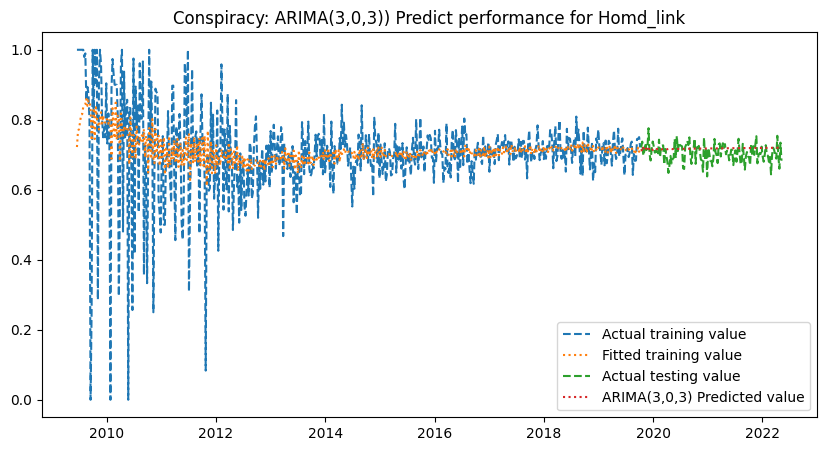

In [ ]:


from statsmodels.tsa.arima.model import ARIMA




model = ARIMA(train["Home_link_filled"], order=(3,0,3))   
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues


forecast_steps = len(test)
predictions = result.forecast(steps=forecast_steps)


predictions = pd.Series(predictions, index=test.index)


plt.figure(figsize=(10, 5))
plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")
plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")


plt.plot(predictions.index, predictions, label="ARIMA(3,0,3) Predicted value", linestyle="dotted")


plt.title("Conspiracy: ARIMA(3,0,3)) Predict performance for Homd_link")
plt.legend()
plt.show()


c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  539
Model:                 ARIMA(3, 0, 3)   Log Likelihood                 371.802
Date:                Tue, 22 Sep 2026   AIC                           -727.604
Time:                        02:45:51   BIC                           -693.286
Sample:                    06-15-2009   HQIC                          -714.181
                         - 10-07-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7221      0.029     24.957      0.000       0.665       0.779
ar.L1         -0.3150      0.067     -4.704      0.000      -0.446      -0.184
ar.L2          0.4728      0.045     10.450      0.0

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\1727476264.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


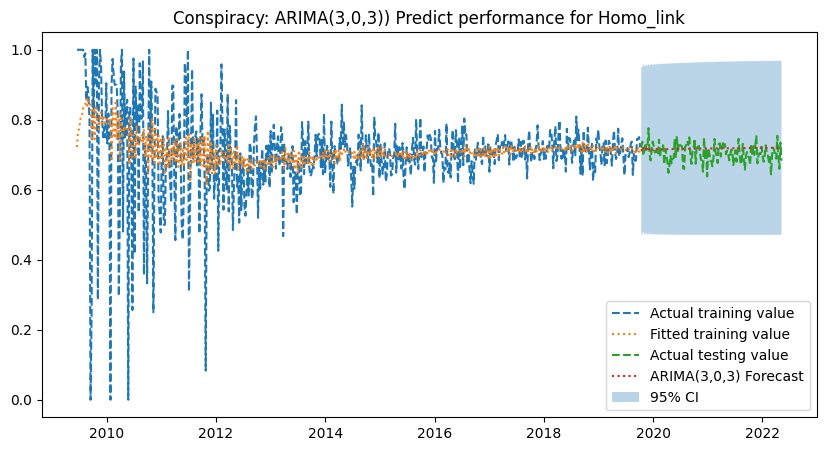

In [ ]:


from statsmodels.tsa.arima.model import ARIMA




model = ARIMA(train["Home_link_filled"], order=(3,0,3))   
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues


forecast_steps = len(test)
forecast_res = result.get_forecast(steps=forecast_steps)

pred_mean = forecast_res.predicted_mean
pred_ci = forecast_res.conf_int(alpha=0.05)  # 95% CI

pred_mean = pd.Series(pred_mean, index=test.index)
pred_ci.index = test.index


plt.figure(figsize=(10, 5))

plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")

plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")
plt.plot(pred_mean.index, pred_mean, label="ARIMA(3,0,3) Forecast", linestyle="dotted")

plt.fill_between(
    test.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.3,
    label="95% CI"
)


plt.title("Conspiracy: ARIMA(3,0,3)) Predict performance for Homo_link")
plt.legend()
plt.show()


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro

residuals = result.resid

ljung_box_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].values[0]


dw_stat = durbin_watson(residuals)


shapiro_p = shapiro(residuals)[1]

print(f"Ljung-Box p-value: {ljung_box_p}")
print(f"Durbin-Watson stat: {dw_stat}")
print(f"Shapiro-Wilk p-value: {shapiro_p}")

Ljung-Box p-value: 0.15595976288403357
Durbin-Watson stat: 2.0173834427765636
Shapiro-Wilk p-value: 1.8997401321124476e-25


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np



eval_df = pd.concat(
    [test["Home_link_filled"], predictions],
    axis=1
)
eval_df.columns = ["y_true", "y_pred"]


eval_df = eval_df.dropna()


mae = mean_absolute_error(eval_df["y_true"], eval_df["y_pred"])
rmse = np.sqrt(mean_squared_error(eval_df["y_true"], eval_df["y_pred"]))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.0231
RMSE: 0.0287


In [ ]:

X = df[["entropy_x_filled","Gini_filled","taaco_filled","density_filled",
                "in-group identity_filled","out-group identity_filled","gender identity_filled","queer identity_filled","disability identity_filled","body size and physical identity_filled","relational identity_filled",
                "professional identity_filled","partisan identity_filled",
                "generational identity_filled","ideological identity_filled","racial identity_filled","class identity_filled","religious identity_filled","national identity_filled",
                "anger_filled","anticipation_filled","disgust_filled","fear_filled","joy_filled","sadness_filled","surprise_filled","trust_filled"]]  
X = sm.add_constant(X)  
y = df["Home_link_filled"]


model = sm.OLS(y, X).fit()
print(model.summary())  

                            OLS Regression Results                            
Dep. Variable:       Home_link_filled   R-squared:                       0.248
Model:                            OLS   Adj. R-squared:                  0.217
Method:                 Least Squares   F-statistic:                     7.891
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           5.53e-26
Time:                        02:46:48   Log-Likelihood:                 613.36
No. Observations:                 674   AIC:                            -1171.
Df Residuals:                     646   BIC:                            -1044.
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [ ]:
exog_train = train[["entropy_x_filled",
    "density_filled","in-group identity_filled","queer identity_filled","disability identity_filled",
    "relational identity_filled","professional identity_filled",
                    "anticipation_filled",
                    
                    "fear_filled", "joy_filled",
                    "surprise_filled","trust_filled"]]  

best_model = auto_arima(train["Home_link_filled"],exogenous=exog_train, seasonal=False, trace=True, stepwise=True)
print(best_model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=inf, Time=0.42 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1175.124, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-407.881, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=648.688, Time=0.03 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=-508.873, Time=0.05 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.08 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=-716.048, Time=0.18 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-716.512, Time=0.11 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=-716.608, Time=0.17 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=309.640, Time=0.06 sec
 ARIMA(1,0,3)(0,0,0)[0]             : AIC=-718.043, Time=0.21 sec
 ARIMA(0,0,3)(0,0,0)[0]             : AIC=151.719, Time=0.08 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=-713.073, Time=0.29 sec
 ARIMA(1,0,4)(0,0,0)[0]             : AIC=-715.841, Time=0.18 sec
 ARIMA(0,0,4)(0,0,0)[0]             : AIC=-3.4

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  539
Model:                 ARIMA(3, 0, 3)   Log Likelihood                 432.309
Date:                Tue, 22 Sep 2026   AIC                           -824.617
Time:                        02:50:07   BIC                           -738.823
Sample:                    06-15-2009   HQIC                          -791.061
                         - 10-07-2019                                         
Covariance Type:                  opg                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.2560      0.107      2.388      0.017       0.046       0.466
entropy_x_filled                 0.0739      0.016      4.642      0.000     

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\1687183294.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


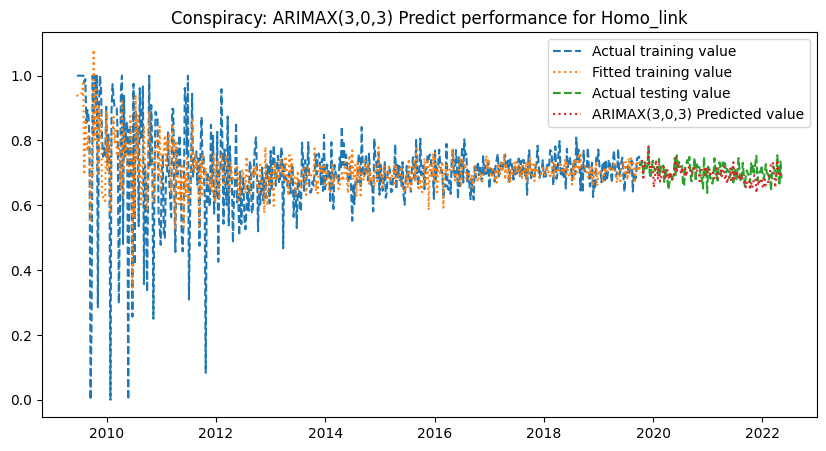

In [ ]:
from statsmodels.tsa.arima.model import ARIMA


exog_train = train[["entropy_x_filled",
    "density_filled","in-group identity_filled","queer identity_filled","disability identity_filled",
    "relational identity_filled","professional identity_filled",
                    "anticipation_filled",
                    
                    "fear_filled", "joy_filled",
                    "surprise_filled","trust_filled"]]  
exog_test = test[["entropy_x_filled",
    "density_filled","in-group identity_filled","queer identity_filled","disability identity_filled",
    "relational identity_filled","professional identity_filled",
                    "anticipation_filled",
                    
                    "fear_filled", "joy_filled",
                    "surprise_filled","trust_filled"]]


model = ARIMA(train["Home_link_filled"], order=(3,0,3), exog=exog_train)
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues

forecast_steps = len(test)

predictions = result.forecast(
    steps=forecast_steps,
    exog=exog_test
)

predictions = pd.Series(predictions, index=test.index)


import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(train.index, train["Home_link_filled"], label="Actual training value", linestyle="--")
plt.plot(train.index, train["Home_link_predicted"], label="Fitted training value", linestyle="dotted")
plt.plot(test.index, test["Home_link_filled"], label="Actual testing value", linestyle="--")


plt.plot(predictions.index, predictions,
        label="ARIMAX(3,0,3) Predicted value", linestyle="dotted")

plt.legend()
plt.title("Conspiracy: ARIMAX(3,0,3) Predict performance for Homo_link")
plt.show()

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:       Home_link_filled   No. Observations:                  539
Model:                 ARIMA(3, 0, 3)   Log Likelihood                 432.309
Date:                Tue, 22 Sep 2026   AIC                           -824.617
Time:                        02:59:04   BIC                           -738.823
Sample:                    06-15-2009   HQIC                          -791.061
                         - 10-07-2019                                         
Covariance Type:                  opg                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.2560      0.107      2.388      0.017       0.046       0.466
entropy_x_filled                 0.0739      0.016      4.642      0.000     

c:\Users\Iris\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Iris\AppData\Local\Temp\ipykernel_6248\4290496563.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train["Home_link_predicted"] = result.fittedvalues


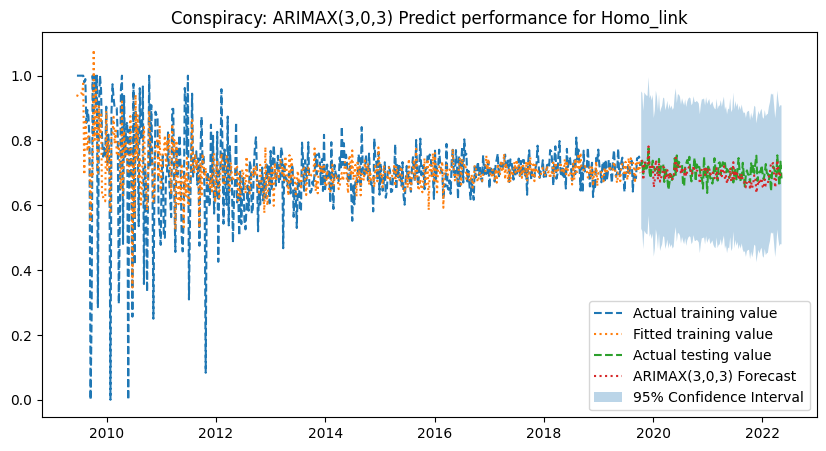

In [ ]:
from statsmodels.tsa.arima.model import ARIMA


exog_train = train[["entropy_x_filled",
    "density_filled","in-group identity_filled","queer identity_filled","disability identity_filled",
    "relational identity_filled","professional identity_filled",
                    "anticipation_filled",
                    
                    "fear_filled", "joy_filled",
                    "surprise_filled","trust_filled"]]  
exog_test = test[["entropy_x_filled",
    "density_filled","in-group identity_filled","queer identity_filled","disability identity_filled",
    "relational identity_filled","professional identity_filled",
                    "anticipation_filled",
                    
                    "fear_filled", "joy_filled",
                    "surprise_filled","trust_filled"]]


model = ARIMA(train["Home_link_filled"], order=(3,0,3), exog=exog_train)
result = model.fit()


print(result.summary())

train["Home_link_predicted"] = result.fittedvalues

# =========================

# =========================
forecast_steps = len(test)

forecast_res = result.get_forecast(
    steps=forecast_steps,
    exog=exog_test
)

pred_mean = forecast_res.predicted_mean
pred_ci = forecast_res.conf_int(alpha=0.05)  # 95% CI


pred_mean = pd.Series(pred_mean, index=test.index)
pred_ci.index = test.index

# =========================

# =========================
plt.figure(figsize=(10, 5))

plt.plot(
    train.index,
    train["Home_link_filled"],
    label="Actual training value",
    linestyle="--"
)

plt.plot(
    train.index,
    train["Home_link_predicted"],
    label="Fitted training value",
    linestyle="dotted"
)

plt.plot(
    test.index,
    test["Home_link_filled"],
    label="Actual testing value",
    linestyle="--"
)

plt.plot(
    pred_mean.index,
    pred_mean,
    label="ARIMAX(3,0,3) Forecast",
    linestyle="dotted"
)

plt.fill_between(
    test.index,
    pred_ci.iloc[:, 0],
    pred_ci.iloc[:, 1],
    alpha=0.3,
    label="95% Confidence Interval"
)


plt.legend()
plt.title("Conspiracy: ARIMAX(3,0,3) Predict performance for Homo_link")
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import shapiro

residuals = result.resid

ljung_box_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].values[0]


dw_stat = durbin_watson(residuals)


shapiro_p = shapiro(residuals)[1]

print(f"Ljung-Box p-value: {ljung_box_p}")
print(f"Durbin-Watson stat: {dw_stat}")
print(f"Shapiro-Wilk p-value: {shapiro_p}")

Ljung-Box p-value: 0.4036961710505289
Durbin-Watson stat: 2.029769233802957
Shapiro-Wilk p-value: 3.6670915464900674e-23


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


eval_df = pd.concat(
    [test["Home_link_filled"], predictions],
    axis=1
)
eval_df.columns = ["y_true", "y_pred"]


eval_df = eval_df.dropna()


mae = mean_absolute_error(eval_df["y_true"], eval_df["y_pred"])
rmse = np.sqrt(mean_squared_error(eval_df["y_true"], eval_df["y_pred"]))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 0.0259
RMSE: 0.0321
